# Makine Öğrenmesi ile Online Alışveriş Satın Alma Niyetinin Tahmin Edilmesi

## 1. Problem Tanımı ve Veri Toplama

### 1.1. Proje Hakkında

Bu proje, çevrimiçi alışveriş sitelerini ziyaret eden kullanıcıların satın alma işlemi gerçekleştirip gerçekleştirmeyeceklerini tahmin etmeyi amaçlamaktadır.

Proje kapsamında kullanıcıların web sitesi üzerindeki gezinme davranışları, oturum bilgileri ve diğer özellikleri analiz edilerek satın alma kararlarını etkileyen faktörler incelenecektir.

Makine öğrenmesi algoritmaları kullanılarak geliştirilecek tahmin modeli sayesinde, satın alma olasılığı yüksek olan ziyaretçilerin belirlenmesi hedeflenmektedir.

### 1.2. İş Problemi

E-ticaret işletmeleri her gün çok sayıda ziyaretçi almakta ancak bu ziyaretçilerin tamamı satın alma işlemi gerçekleştirmemektedir. Bu durum, işletmelerin pazarlama kaynaklarını doğru hedef kitleye yönlendirmesini zorlaştırmaktadır.

Bu projenin temel iş problemi, çevrimiçi alışveriş yapan ziyaretçiler arasından satın alma gerçekleştirme olasılığı yüksek olan kullanıcıları belirlemektir.

Geliştirilecek makine öğrenmesi modeli ile işletmelerin pazarlama stratejilerini iyileştirmelerine, dönüşüm oranlarını artırmalarına ve müşteri davranışlarını daha iyi anlamalarına katkı sağlanması amaçlanmaktadır.

### 1.3. Veri Kaynağı ve Toplama Yöntemi

Bu projede, UCI Machine Learning Repository platformunda yayımlanan "Online Shoppers Purchasing Intention Dataset" veri seti kullanılacaktır.

Veri seti, C. Sakar ve Yomi Kastro tarafından hazırlanmış ve 2018 yılında yayımlanmıştır. Toplam 12.330 çevrimiçi alışveriş oturumuna ait verilerden oluşmaktadır. Her satır, farklı bir kullanıcıya ait bir ziyaret oturumunu temsil etmektedir.

Veriler; ziyaretçilerin web sitesinde gezindikleri sayfa sayıları, sayfalarda geçirdikleri süreler, ziyaret ayı, ziyaretçi türü ve hafta sonu bilgisi gibi değişkenleri içermektedir. Veri setindeki `Revenue` değişkeni, ilgili oturumun satın alma işlemiyle sonuçlanıp sonuçlanmadığını göstermektedir.

Veri seti, UCI Machine Learning Repository'nin resmî internet sitesi üzerinden CSV formatında elde edilmiştir.


In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv("online_shoppers_intention.csv")

df.head()

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


In [2]:
# Veri setinin boyutlarını inceleyelim
print("Veri setinin boyutu:", df.shape)

# Sütun isimlerini inceleyelim
print("\nSütun isimleri:")
print(df.columns.tolist())

# Veri seti hakkında genel bilgi
print("\nVeri seti bilgileri:")
df.info()

# Satın alma yapan ve yapmayan oturumların sayısı
print("\nSatın alma dağılımı:")
print(df["Revenue"].value_counts())

Veri setinin boyutu: (12330, 18)

Sütun isimleri:
['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay', 'Month', 'OperatingSystems', 'Browser', 'Region', 'TrafficType', 'VisitorType', 'Weekend', 'Revenue']

Veri seti bilgileri:
<class 'pandas.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float6

### 1.4. Veri Setinin Genel Yapısı

Veri seti üzerinde yapılan ilk incelemede toplam 12.330 alışveriş oturumu ve 18 sütun bulunduğu görülmüştür. Bu sütunların 17'si bağımsız değişkenlerden, 1'i ise hedef değişken olan Revenue sütunundan oluşmaktadır.

Veri setinde ziyaretçilerin web sitesindeki gezinme davranışlarını, sayfa ziyaret sayılarını, sayfalarda geçirdikleri süreleri, trafik kaynaklarını ve ziyaret özelliklerini temsil eden değişkenler bulunmaktadır.

Veri türleri incelendiğinde sayısal, kategorik ve mantıksal (boolean) değişkenlerin bir arada bulunduğu görülmüştür. İlk incelemede sütunlarda eksik değer tespit edilmemiştir.

Revenue değişkeninin dağılımına göre 10.422 oturumda satın alma gerçekleşmemiş, 1.908 oturumda ise satın alma gerçekleşmiştir. Buna göre oturumların yaklaşık %84,53'ünde satın alma yapılmazken %15,47'sinde satın alma gerçekleşmiştir.

Bu dağılım, veri setinde sınıf dengesizliği bulunduğunu göstermektedir. Bu nedenle model geliştirme aşamasında yalnızca doğruluk oranına değil, Precision, Recall ve F1-score gibi performans ölçütlerine de önem verilecektir.

### 1.5. İş Başarı Kriterleri

Bu projenin başarısı yalnızca makine öğrenmesi modelinin tahmin doğruluğuyla değil, işletmeye sağlayabileceği potansiyel katkılarla da değerlendirilecektir.

Projenin temel iş başarı kriteri, satın alma gerçekleştirme olasılığı yüksek olan alışveriş oturumlarının doğru şekilde belirlenmesidir.

Geliştirilecek modelin aşağıdaki konularda işletmelere katkı sağlaması hedeflenmektedir:

- Pazarlama kampanyalarının satın alma olasılığı yüksek ziyaretçilere yönlendirilmesine yardımcı olmak.
- Pazarlama kaynaklarının daha verimli kullanılmasını desteklemek.
- Satın alma davranışını etkileyen faktörlerin belirlenmesini sağlamak.
- Potansiyel müşterilere yönelik daha etkili pazarlama stratejileri geliştirilmesine katkıda bulunmak.

Modelin teknik başarısı Precision, Recall, F1-score ve Accuracy gibi performans ölçütleriyle değerlendirilecektir. Özellikle satın alma gerçekleştiren oturumların ne kadarının doğru tespit edildiğini gösteren Recall ve yapılan satın alma tahminlerinin ne kadarının doğru olduğunu gösteren Precision değerleri önem taşıyacaktır.


In [3]:
# Her sütundaki eksik değer sayısını hesaplayalım
missing_values = df.isnull().sum()

# Eksik değer yüzdelerini hesaplayalım
missing_percentages = (df.isnull().sum() / len(df)) * 100

# Sonuçları tablo halinde gösterelim
missing_table = pd.DataFrame({
    "Eksik Değer Sayısı": missing_values,
    "Eksik Değer Yüzdesi (%)": missing_percentages
})

print(missing_table)

                         Eksik Değer Sayısı  Eksik Değer Yüzdesi (%)
Administrative                            0                      0.0
Administrative_Duration                   0                      0.0
Informational                             0                      0.0
Informational_Duration                    0                      0.0
ProductRelated                            0                      0.0
ProductRelated_Duration                   0                      0.0
BounceRates                               0                      0.0
ExitRates                                 0                      0.0
PageValues                                0                      0.0
SpecialDay                                0                      0.0
Month                                     0                      0.0
OperatingSystems                          0                      0.0
Browser                                   0                      0.0
Region                            

### 2.1. Eksik Verilerin Kontrolü ve Yönetimi

Veri setindeki eksik değerler, her sütun için ayrı ayrı incelenmiş ve eksik değer sayıları ile yüzdeleri hesaplanmıştır.

Yapılan inceleme sonucunda 12.330 gözlemden oluşan veri setindeki 18 sütunun hiçbirinde eksik değer bulunmadığı tespit edilmiştir. Tüm değişkenlerin eksik değer oranı %0'dır.

Bu nedenle eksik verilerin ortalama, medyan veya mod gibi yöntemlerle doldurulmasına ya da eksik veri içeren kayıtların silinmesine ihtiyaç duyulmamıştır. Veri seti eksik değerler açısından mevcut haliyle korunmuştur.

In [4]:
# Tekrarlanan satırların sayısını kontrol edelim
duplicate_count = df.duplicated().sum()

print("Tekrarlanan kayıt sayısı:", duplicate_count)

# Tekrarlanan kayıtların veri setindeki yüzdesi
duplicate_percentage = (duplicate_count / len(df)) * 100

print("Tekrarlanan kayıt yüzdesi: %", round(duplicate_percentage, 2))

Tekrarlanan kayıt sayısı: 125
Tekrarlanan kayıt yüzdesi: % 1.01


### 2.2. Tekrarlanan Kayıtların Kontrolü ve Temizlenmesi

Veri setinde tekrarlanan kayıtların bulunup bulunmadığını belirlemek amacıyla tüm sütunlar üzerinden tekrar kontrolü yapılmıştır.

İnceleme sonucunda 125 adet tamamen aynı satır tespit edilmiştir. Bu sayı toplam gözlemlerin yaklaşık %1,01'ine karşılık gelmektedir.

Tekrarlanan kayıtların modelleme sürecinde aynı gözlemlerin birden fazla kez değerlendirilmesini önlemek amacıyla bu satırlar veri setinden çıkarılmıştır.

Temizlik işlemi sonucunda veri setindeki gözlem sayısı 12.330'dan 12.205'e düşmüştür.

Veri setinde her alışveriş oturumu için benzersiz bir kimlik bulunmadığından, tamamen aynı özelliklere sahip bazı kayıtların gerçekte farklı oturumları temsil etme ihtimali bulunmaktadır. Bu durum veri setinin bir kısıtı olarak değerlendirilmiştir.

In [5]:
# Orijinal veri setinin yedeğini alalım
df_original = df.copy()

# Tekrarlanan kayıtları temizleyelim
df = df.drop_duplicates().copy()

# Temizlik öncesi ve sonrası kayıt sayılarını karşılaştıralım
print("Temizlik öncesi kayıt sayısı:", len(df_original))
print("Silinen tekrarlanan kayıt sayısı:", len(df_original) - len(df))
print("Temizlik sonrası kayıt sayısı:", len(df))

# Tekrarlanan kayıtları yeniden kontrol edelim
print("Kalan tekrarlanan kayıt sayısı:", df.duplicated().sum())

Temizlik öncesi kayıt sayısı: 12330
Silinen tekrarlanan kayıt sayısı: 125
Temizlik sonrası kayıt sayısı: 12205
Kalan tekrarlanan kayıt sayısı: 0


Veri setinde tekrarlanan kayıtların bulunup bulunmadığını belirlemek amacıyla tüm sütunlar üzerinden kontrol yapılmıştır.

İlk inceleme sonucunda 125 adet tekrarlanan kayıt tespit edilmiştir. Bu sayı toplam gözlem sayısının yaklaşık %1,01'ine karşılık gelmektedir.

Tekrarlanan kayıtlar drop_duplicates() fonksiyonu kullanılarak veri setinden çıkarılmıştır. Temizlik işlemi sonucunda kayıt sayısı 12.330'dan 12.205'e düşmüştür.

Temizlik sonrasında yapılan kontrol sonucunda veri setinde tekrarlanan kayıt kalmadığı doğrulanmıştır.

Bu işlemle aynı kayıtların analiz ve modelleme sürecinde birden fazla kez yer almasının önüne geçilmiştir.

In [7]:
numerical_columns = [
    "Administrative",
    "Administrative_Duration",
    "Informational",
    "Informational_Duration",
    "ProductRelated",
    "ProductRelated_Duration",
    "BounceRates",
    "ExitRates",
    "PageValues",
    "SpecialDay"
]

outlier_results = []

for column in numerical_columns:
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outlier_count = (
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    ).sum()

    outlier_percentage = (outlier_count / len(df)) * 100

    outlier_results.append({
        "Değişken": column,
        "Aykırı Değer Sayısı": outlier_count,
        "Aykırı Değer Yüzdesi (%)": round(outlier_percentage, 2)
    })

outlier_table = pd.DataFrame(outlier_results)

print(outlier_table)

                  Değişken  Aykırı Değer Sayısı  Aykırı Değer Yüzdesi (%)
0           Administrative                  404                      3.31
1  Administrative_Duration                 1149                      9.41
2            Informational                 2631                     21.56
3   Informational_Duration                 2405                     19.71
4           ProductRelated                 1007                      8.25
5  ProductRelated_Duration                  951                      7.79
6              BounceRates                 1428                     11.70
7                ExitRates                 1325                     10.86
8               PageValues                 2730                     22.37
9               SpecialDay                 1249                     10.23


2.3. Aykırı Değerlerin Tespiti ve Değerlendirilmesi

Veri setindeki aykırı değerleri belirlemek amacıyla IQR (Interquartile Range – Çeyrekler Açıklığı) yöntemi kullanılmıştır. Bu yöntemde birinci ve üçüncü çeyrek değerleri arasındaki fark hesaplanarak alt ve üst sınırlar belirlenmiştir. Belirlenen sınırların dışında kalan gözlemler aykırı değer adayı olarak değerlendirilmiştir.

Analiz sonucunda en yüksek aykırı değer oranı %22,37 ile PageValues değişkeninde tespit edilmiştir. Bunu %21,56 ile Informational ve %19,71 ile Informational_Duration değişkenleri takip etmektedir. Administrative_Duration değişkeninde %9,41, ProductRelated değişkeninde %8,25 ve ProductRelated_Duration değişkeninde %7,79 oranında aykırı değer belirlenmiştir. BounceRates, ExitRates ve SpecialDay değişkenlerinde de aykırı değerler tespit edilmiştir.

Elde edilen sonuçlar, ziyaretçilerin web sitesindeki gezinme davranışları arasında belirgin farklılıklar bulunduğunu göstermektedir. Özellikle bazı ziyaretçilerin diğerlerine kıyasla daha fazla sayfa incelemesi veya sayfalarda daha uzun süre geçirmesi mümkündür.

Bu nedenle tespit edilen aykırı değerlerin tamamı hatalı veri olarak kabul edilmemiştir. Gerçek kullanıcı davranışlarını temsil edebilecekleri göz önünde bulundurularak bu aşamada silinmemelerine karar verilmiştir. Böylece veri setindeki potansiyel olarak değerli gözlemlerin korunması amaçlanmıştır.

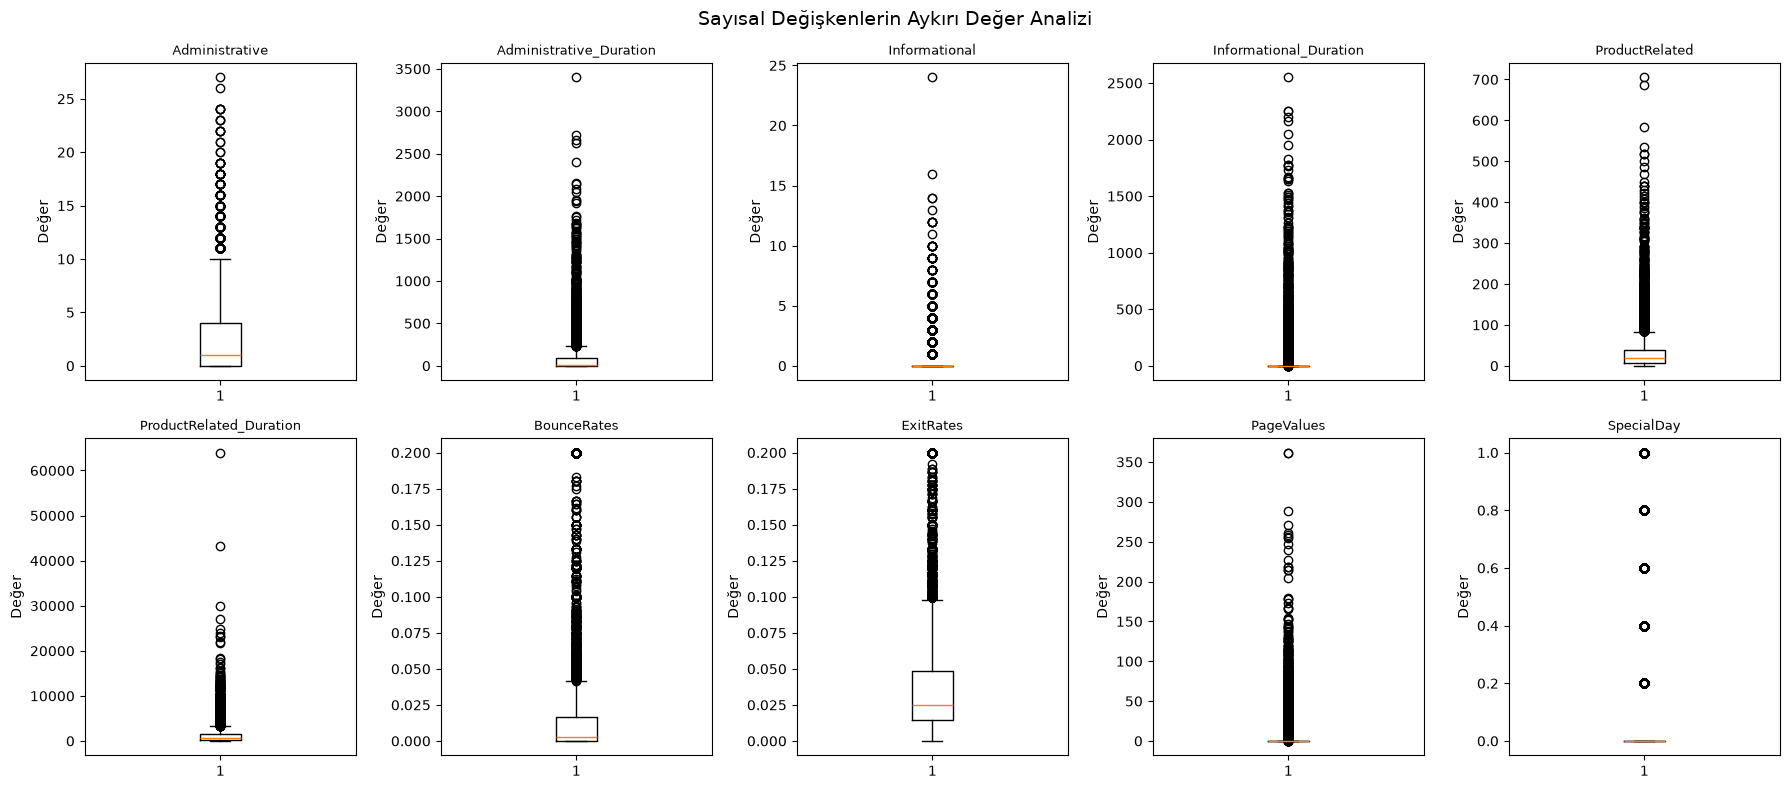

In [8]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 5, figsize=(18, 8))

for ax, column in zip(axes.flatten(), numerical_columns):
    ax.boxplot(df[column])
    ax.set_title(column, fontsize=9)
    ax.set_ylabel("Değer")

plt.suptitle("Sayısal Değişkenlerin Aykırı Değer Analizi", fontsize=14)
plt.tight_layout()
plt.show()

2.3.1. Aykırı Değerlerin Görselleştirilmesi

Aykırı değer analizini desteklemek amacıyla sayısal değişkenlerin dağılımları Boxplot grafikleri kullanılarak görselleştirilmiştir.

Grafiklerde kutu ve bıyıkların dışında kalan noktalar, IQR yöntemine göre aykırı değer olarak belirlenen gözlemleri temsil etmektedir. Değişkenlerin dağılımlarının birbirinden farklı olduğu ve bazı değişkenlerde aykırı değerlerin daha yoğun bulunduğu görülmektedir.

Aykırı değerlerin gerçek kullanıcı davranışlarından kaynaklanma ihtimali nedeniyle bu aşamada herhangi bir gözlem silinmemiştir. Bu değerlerin model performansına etkisi, modelleme aşamasında değerlendirilecektir.

In [9]:
# Kategorik değişkenleri belirleyelim
categorical_columns = df.select_dtypes(
    include=["object", "str", "bool"]
).columns.tolist()

print("Kategorik değişkenler:")
print(categorical_columns)

# Her kategorik değişkenin farklı değerlerini inceleyelim
for column in categorical_columns:
    print("\n", column)
    print(df[column].value_counts())

Kategorik değişkenler:
['Month', 'VisitorType', 'Weekend', 'Revenue']

 Month
Month
May     3329
Nov     2982
Mar     1860
Dec     1706
Oct      549
Sep      448
Aug      433
Jul      432
June     285
Feb      181
Name: count, dtype: int64

 VisitorType
VisitorType
Returning_Visitor    10431
New_Visitor           1693
Other                   81
Name: count, dtype: int64

 Weekend
Weekend
False    9346
True     2859
Name: count, dtype: int64

 Revenue
Revenue
False    10297
True      1908
Name: count, dtype: int64


Revenue hedef değişkenim. Diğer değişkenden ayrı tutacağım. Örneğin month değişkenini 1, 2, 3 şeklinde kodlarsak model aylar arasında sayısal bir sıralama veya mesafe varmış gibi yorumlayabilir. One-Hot Encoding ise her kategoriyi ayrı bir sütun olarak temsil eder.

2.4. Kategorik Değişkenlerin İncelenmesi ve Kodlanması

Veri setindeki kategorik değişkenler incelendiğinde Month, VisitorType, Weekend ve Revenue olmak üzere dört değişken belirlenmiştir.

Month değişkeni alışveriş oturumunun gerçekleştiği ayı, VisitorType değişkeni ziyaretçinin türünü, Weekend değişkeni ziyaretin hafta sonunda gerçekleşip gerçekleşmediğini ve Revenue değişkeni satın alma durumunu temsil etmektedir.

Makine öğrenmesi algoritmalarının kategorik verileri işleyebilmesi için uygun kodlama yöntemleri kullanılacaktır.

Month ve VisitorType değişkenleri One-Hot Encoding yöntemiyle sayısal sütunlara dönüştürülecektir.

Weekend değişkeni False ve True değerleri sırasıyla 0 ve 1 olarak kodlanacaktır.

Revenue hedef değişkeni de False ve True değerleri sırasıyla 0 ve 1 olarak dönüştürülecektir.

Kodlama işlemlerinde kategorik değişkenlerin yapısının korunmasına dikkat edilecektir. One-Hot Encoding işlemi, veri sızıntısını önlemek amacıyla eğitim ve test verileri ayrıldıktan sonra yalnızca eğitim verisi üzerinde öğrenilecektir.

2.5. Sayısal Değişkenlerin Ölçeklendirilmesi

Veri setindeki sayısal değişkenlerin farklı değer aralıklarına sahip olduğu görülmüştür. Özellikle sayfa ziyaret sayıları, sayfalarda geçirilen süreler ve oran değişkenleri farklı ölçeklerde ölçülmektedir.

Bu farklılıkların bazı makine öğrenmesi algoritmalarının performansını olumsuz etkilemesini önlemek amacıyla StandardScaler yöntemi kullanılacaktır.

StandardScaler, değişkenleri ortalaması 0 ve standart sapması 1 olacak şekilde dönüştürür.

Ölçeklendirme işlemi, veri sızıntısını önlemek amacıyla eğitim ve test verileri ayrıldıktan sonra gerçekleştirilecektir. Ölçeklendirme parametreleri yalnızca eğitim verisi kullanılarak hesaplanacak, aynı dönüşüm test verisine uygulanacaktır.

2.6. Veri Hazırlama Sürecinin Genel Değerlendirmesi

Veri hazırlama aşamasında öncelikle eksik değerler ve tekrarlanan kayıtlar kontrol edilmiştir. Veri setinde eksik değer bulunmadığı belirlenmiş, 125 adet tekrarlanan kayıt temizlenmiştir.

IQR yöntemiyle aykırı değer adayları tespit edilmiş ancak bu değerlerin gerçek kullanıcı davranışlarını temsil etme ihtimali nedeniyle silinmemesine karar verilmiştir.

Kategorik değişkenler için One-Hot Encoding ve ikili değişkenler için 0-1 dönüşümü planlanmıştır. Sayısal değişkenlerin ölçeklendirilmesinde ise StandardScaler yönteminin kullanılması uygun görülmüştür.

Kodlama ve ölçeklendirme işlemleri, veri sızıntısını önlemek amacıyla eğitim ve test verileri ayrıldıktan sonra bir ön işleme süreci içerisinde gerçekleştirilecektir.

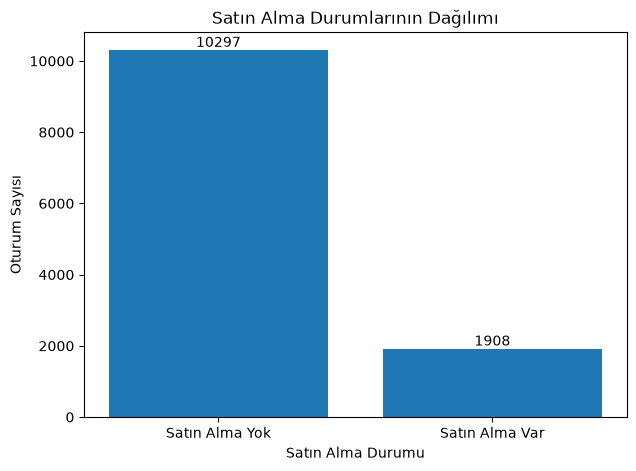

In [10]:
import matplotlib.pyplot as plt

# Satın alma durumlarının sayısını hesaplayalım
revenue_counts = df["Revenue"].value_counts().sort_index()

# Grafik oluşturalım
plt.figure(figsize=(7, 5))

plt.bar(
    ["Satın Alma Yok", "Satın Alma Var"],
    revenue_counts.values
)

plt.title("Satın Alma Durumlarının Dağılımı")
plt.xlabel("Satın Alma Durumu")
plt.ylabel("Oturum Sayısı")

# Çubukların üzerine sayıları yazdıralım
for i, value in enumerate(revenue_counts.values):
    plt.text(i, value + 100, str(value), ha="center")

plt.show()

3.1. Hedef Değişkenin Dağılımı

Veri setindeki hedef değişken olan Revenue incelenerek satın alma gerçekleştiren ve gerçekleştirmeyen oturumların dağılımı görselleştirilmiştir.

Toplam 12.205 oturumun 10.297'sinde (%84,37) satın alma gerçekleşmemiş, 1.908'inde (%15,63) ise satın alma gerçekleşmiştir.

Bu sonuçlar, veri setinde satın alma gerçekleştirmeyen oturumların belirgin şekilde daha fazla olduğunu göstermektedir. Dolayısıyla hedef değişkende sınıf dengesizliği bulunmaktadır.

Bu durum modelleme sürecinde dikkate alınacaktır. Model performansının değerlendirilmesinde Accuracy metriğinin yanı sıra Precision, Recall ve F1-score gibi ölçütlerden de yararlanılacaktır.

In [11]:
# Ziyaretçi türüne göre satın alma oranlarını hesaplayalım
visitor_purchase = pd.crosstab(
    df["VisitorType"],
    df["Revenue"],
    normalize="index"
) * 100

print(visitor_purchase)

Revenue                False      True 
VisitorType                            
New_Visitor        75.073833  24.926167
Other              80.246914  19.753086
Returning_Visitor  85.907391  14.092609


3.2. Ziyaretçi Türüne Göre Satın Alma Oranlarının İncelenmesi

Ziyaretçi türü (VisitorType) ile satın alma durumu (Revenue) arasındaki ilişki incelenmiştir. Her ziyaretçi grubunun kendi içerisindeki satın alma ve satın almama oranları hesaplanmıştır.

Analiz sonucunda, yeni ziyaretçilerin (New Visitor) satın alma oranının %24,93 olduğu görülmüştür. Tekrar gelen ziyaretçilerde (Returning Visitor) bu oran %14,09, diğer ziyaretçi grubunda (Other) ise %19,75 olarak hesaplanmıştır.

Bu sonuçlar, yeni ziyaretçilerin satın alma gerçekleştirme oranının diğer ziyaretçi gruplarına göre daha yüksek olduğunu göstermektedir. Tekrar gelen ziyaretçilerin ise satın alma gerçekleştirmeme oranı en yüksek gruptur.

VisitorType değişkeninin satın alma davranışını tahmin etmede yararlı bir özellik olabileceği düşünülmektedir. Bu ilişkinin modelleme aşamasında da değerlendirilmesi planlanmaktadır.

In [12]:
# Satın alma durumuna göre sayfa görüntüleme ortalamaları

page_columns = [
    "Administrative",
    "Informational",
    "ProductRelated"
]

df.groupby("Revenue")[page_columns].mean()

,Administrative,Informational,ProductRelated
Revenue,,,
False,2.143440,0.457318,29.050403
True,3.393606,0.786164,48.210168


3.3. Sayfa Görüntüleme Davranışları ile Satın Alma İlişkisinin İncelenmesi

Ziyaretçilerin farklı sayfa türlerinde gerçekleştirdikleri görüntüleme sayıları, satın alma durumlarına göre karşılaştırılmıştır. Bu kapsamda Administrative, Informational ve ProductRelated değişkenlerinin ortalamaları incelenmiştir.

Analiz sonucunda, satın alma gerçekleştiren ziyaretçilerin üç sayfa türünde de daha yüksek görüntüleme ortalamasına sahip olduğu görülmüştür.

En belirgin fark ProductRelated değişkeninde ortaya çıkmıştır. Satın alma gerçekleştiren ziyaretçiler ortalama 48,21 ürün sayfası görüntülerken satın alma gerçekleştirmeyen ziyaretçilerde bu değer 29,05'tir.

Bu bulgular, ziyaretçilerin özellikle ürün sayfalarını daha fazla incelemesinin satın alma davranışıyla ilişkili olabileceğini göstermektedir. Dolayısıyla sayfa görüntüleme sayıları, satın alma niyetinin tahmin edilmesinde yararlı özellikler olabilir.

In [13]:
# Satın alma durumuna göre sayfalarda geçirilen ortalama süre

duration_columns = [
    "Administrative_Duration",
    "Informational_Duration",
    "ProductRelated_Duration"
]

df.groupby("Revenue")[duration_columns].mean()

,Administrative_Duration,Informational_Duration,ProductRelated_Duration
Revenue,,,
False,74.635276,30.603289,1082.976881
True,119.483244,57.611427,1876.209615


3.3.2. Sayfalarda Geçirilen Sürenin Satın Alma ile İlişkisinin İncelenmesi

Ziyaretçilerin farklı sayfa türlerinde geçirdikleri ortalama süreler, satın alma durumlarına göre karşılaştırılmıştır. Bu kapsamda Administrative_Duration, Informational_Duration ve ProductRelated_Duration değişkenleri incelenmiştir.

Analiz sonucunda, satın alma gerçekleştiren ziyaretçilerin üç sayfa türünde de daha fazla zaman geçirdiği görülmüştür.

En belirgin fark ürün sayfalarında geçirilen sürede ortaya çıkmıştır. Satın alma gerçekleştiren ziyaretçiler ürün sayfalarında ortalama 1.876,21 saniye geçirirken satın alma gerçekleştirmeyen ziyaretçilerde bu değer 1.082,98 saniyedir.

Bu bulgular, ziyaretçilerin sayfalarda geçirdikleri sürenin satın alma davranışıyla ilişkili olabileceğini göstermektedir. Özellikle ürün sayfalarında geçirilen süre, satın alma niyetinin tahmin edilmesinde yararlı bir değişken olabilir.

In [14]:
# Satın alma durumuna göre oturum davranışı değişkenlerinin ortalamaları

behavior_columns = [
    "BounceRates",
    "ExitRates",
    "PageValues"
]

df.groupby("Revenue")[behavior_columns].mean()

,BounceRates,ExitRates,PageValues
Revenue,,,
False,0.023197,0.045526,1.999985
True,0.005117,0.019555,27.264518


3.4. Oturum Davranışlarının Satın Alma ile İlişkisinin İncelenmesi

Ziyaretçilerin site içerisindeki davranışlarını değerlendirmek amacıyla BounceRates, ExitRates ve PageValues değişkenleri satın alma durumuna göre karşılaştırılmıştır.

Analiz sonucunda, satın alma gerçekleştiren oturumlarda BounceRates ve ExitRates ortalamalarının daha düşük olduğu görülmüştür. Bu durum, satın alma yapan ziyaretçilerin siteyle daha fazla etkileşim kurduğunu düşündürmektedir.

PageValues değişkeninde ise belirgin bir farklılık bulunmaktadır. Satın alma gerçekleştiren oturumlarda PageValues ortalaması 27,26 iken satın alma gerçekleştirmeyen oturumlarda yaklaşık 2,00 olarak hesaplanmıştır.

Bu sonuçlar, oturum davranışlarını yansıtan değişkenlerin satın alma tahmininde önemli bilgiler sağlayabileceğini göstermektedir. Ancak özellikle PageValues değişkeninin satın alma davranışıyla çok güçlü ilişkisi bulunduğundan, modelleme aşamasında bu değişkenin tahmin sürecinde veri sızıntısına yol açıp açmayacağı ayrıca değerlendirilecektir.

In [15]:
# Aylara göre satın alma oranları

monthly_purchase = pd.crosstab(
    df["Month"],
    df["Revenue"],
    normalize="index"
) * 100

monthly_purchase = monthly_purchase.sort_values(
    by=True,
    ascending=False
)

monthly_purchase

Revenue,False,True
Month,,
Nov,74.513749,25.486251
Oct,79.052823,20.947177
Sep,80.803571,19.196429
Aug,82.448037,17.551963
Jul,84.722222,15.277778
Dec,87.338804,12.661196
May,89.035746,10.964254
Mar,89.677419,10.322581
June,89.824561,10.175439


3.5. Aylara Göre Satın Alma Oranlarının İncelenmesi

Satın alma davranışının yılın farklı aylarına göre değişip değişmediğini incelemek amacıyla Month değişkeni analiz edilmiştir. Her ay için satın alma gerçekleştiren ve gerçekleştirmeyen oturumların yüzdesi hesaplanmıştır.

Analiz sonucunda, kasım ayı %25,49 ile en yüksek satın alma oranına sahip ay olarak belirlenmiştir. Ekim ayında bu oran %20,95, eylül ayında ise %19,20'dir. Şubat ayı ise %1,66 ile en düşük satın alma oranına sahiptir.

Bu bulgular, satın alma davranışının aylara göre farklılık gösterebileceğini ortaya koymaktadır. Ancak aylardaki oturum sayılarının farklı olması nedeniyle sonuçlar değerlendirilirken gözlem sayıları da dikkate alınmalıdır. Month değişkeninin satın alma tahmininde yararlı olabilecek bir özellik olduğu düşünülmektedir.

In [16]:
# Hafta içi ve hafta sonu satın alma oranları

weekend_purchase = pd.crosstab(
    df["Weekend"],
    df["Revenue"],
    normalize="index"
) * 100

weekend_purchase.index = ["Hafta İçi", "Hafta Sonu"]

weekend_purchase

Revenue,False,True
Hafta İçi,84.924032,15.075968
Hafta Sonu,82.546345,17.453655


3.5.2. Hafta İçi ve Hafta Sonu Satın Alma Oranlarının İncelenmesi

Ziyaret zamanının satın alma davranışıyla ilişkisini değerlendirmek amacıyla Weekend değişkeni incelenmiştir. Hafta içi ve hafta sonu oturumlarının satın alma oranları karşılaştırılmıştır.

Analiz sonucunda, hafta sonu oturumlarında satın alma oranı %17,45, hafta içi oturumlarında ise %15,08 olarak hesaplanmıştır. Buna göre hafta sonu satın alma oranı yaklaşık 2,38 yüzde puan daha yüksektir.

Bu sonuç, hafta sonu ziyaretlerinde satın alma oranının bir miktar daha yüksek olduğunu göstermektedir. Ancak iki grup arasındaki farkın sınırlı olması nedeniyle Weekend değişkeninin etkisi modelleme aşamasında diğer değişkenlerle birlikte değerlendirilmelidir.

In [17]:
# Özel gün değerlerine göre satın alma oranları

specialday_purchase = pd.crosstab(
    df["SpecialDay"],
    df["Revenue"],
    normalize="index"
) * 100

specialday_purchase

Revenue,False,True
SpecialDay,,
0.0,83.287696,16.712304
0.2,92.134831,7.865169
0.4,94.650206,5.349794
0.6,91.714286,8.285714
0.8,96.604938,3.395062
1.0,93.506494,6.493506


3.6. Özel Günlerin Satın Alma Davranışıyla İlişkisinin İncelenmesi

Özel günlere yakınlığın satın alma davranışıyla ilişkisini incelemek amacıyla SpecialDay değişkeni analiz edilmiştir. Bu değişkenin farklı değerlerinde satın alma gerçekleştiren ve gerçekleştirmeyen oturumların oranları hesaplanmıştır.

Analiz sonucunda, SpecialDay değeri 0.0 olan oturumlarda satın alma oranı %16,71 ile en yüksek seviyededir. Diğer değerlerde satın alma oranları daha düşük bulunmuştur. En düşük satın alma oranı ise 0.8 değerinde %3,40 olarak hesaplanmıştır.

Sonuçlar, özel günlere yakınlığın satın alma oranını düzenli olarak artırmadığını göstermektedir. Bu nedenle SpecialDay değişkeninin tahmin modeline katkısı diğer değişkenlerle birlikte değerlendirilmelidir.

In [18]:
# Her özel gün değerindeki oturum sayıları

df["SpecialDay"].value_counts().sort_index()

SpecialDay
0.0    10956
0.2      178
0.4      243
0.6      350
0.8      324
1.0      154
Name: count, dtype: int64

3.6.1. SpecialDay Değişkeninin Gözlem Dağılımının Değerlendirilmesi

SpecialDay değişkeninin farklı değerlerine ait oturum sayıları incelenmiştir. Toplam 12.205 oturumun 10.956'sının (%89,8) SpecialDay değerinin 0.0 olduğu görülmüştür. Diğer değerlerdeki gözlem sayıları ise 154 ile 350 arasında değişmektedir.

Bu dağılım, veri setindeki oturumların büyük çoğunluğunun özel gün dönemleri dışında gerçekleştiğini göstermektedir. Dolayısıyla diğer SpecialDay gruplarındaki satın alma oranları daha az sayıda gözleme dayanmaktadır ve dikkatli yorumlanmalıdır.

Bu değişkenin model performansına katkısı modelleme aşamasında ayrıca değerlendirilecektir.

In [19]:
# Yeni özelliklerin oluşturulması

df["TotalPages"] = (
    df["Administrative"] +
    df["Informational"] +
    df["ProductRelated"]
)

df["TotalDuration"] = (
    df["Administrative_Duration"] +
    df["Informational_Duration"] +
    df["ProductRelated_Duration"]
)

df[[
    "Administrative",
    "Informational",
    "ProductRelated",
    "TotalPages",
    "TotalDuration"
]].head()

,Administrative,Informational,ProductRelated,TotalPages,TotalDuration
0,0,0,1,1,0.000000
1,0,0,2,2,64.000000
2,0,0,1,1,0.000000
3,0,0,2,2,2.666667
4,0,0,10,10,627.500000


3.7. Özellik Mühendisliği (Feature Engineering)

Modelin tahmin performansını geliştirebilecek yeni değişkenler oluşturmak amacıyla özellik mühendisliği uygulanmıştır. Bu kapsamda mevcut sayfa görüntüleme ve süre değişkenlerinden yararlanılarak iki yeni özellik oluşturulmuştur.

TotalPages: Administrative, Informational ve ProductRelated değişkenlerinin toplamından elde edilmiştir. Ziyaretçinin oturum boyunca görüntülediği toplam sayfa sayısını temsil etmektedir.

TotalDuration: Administrative_Duration, Informational_Duration ve ProductRelated_Duration değişkenlerinin toplamından elde edilmiştir. Ziyaretçinin oturum boyunca sayfalarda geçirdiği toplam süreyi göstermektedir.

Bu yeni değişkenlerle ziyaretçilerin genel gezinme yoğunluğunun ve sitede geçirdikleri toplam sürenin satın alma davranışını tahmin etmede yararlı olup olmadığı araştırılacaktır.

In [20]:
# Ürün sayfası başına ortalama geçirilen süre

df["AverageProductPageDuration"] = np.where(
    df["ProductRelated"] > 0,
    df["ProductRelated_Duration"] / df["ProductRelated"],
    0
)

df[[
    "ProductRelated",
    "ProductRelated_Duration",
    "AverageProductPageDuration"
]].head(10)

,ProductRelated,ProductRelated_Duration,AverageProductPageDuration
0,1,0.000000,0.000000
1,2,64.000000,32.000000
2,1,0.000000,0.000000
3,2,2.666667,1.333333
4,10,627.500000,62.750000
5,19,154.216667,8.116667
6,1,0.000000,0.000000
7,0,0.000000,0.000000
8,2,37.000000,18.500000
9,3,738.000000,246.000000


3.7.1. Ürün Sayfası Başına Ortalama Geçirilen Sürenin Oluşturulması

Ürün sayfalarında geçirilen süreyi daha ayrıntılı incelemek amacıyla AverageProductPageDuration isimli yeni bir değişken oluşturulmuştur. Bu değişken, ProductRelated_Duration değerinin ProductRelated değerine bölünmesiyle hesaplanmıştır.

Böylece ziyaretçilerin bir ürün sayfasında ortalama ne kadar zaman geçirdiği ölçülmüştür. Hiç ürün sayfası görüntülemeyen oturumlarda sıfıra bölme hatasını önlemek amacıyla ilgili değer 0 olarak belirlenmiştir.

Bu özellik sayesinde yalnızca toplam geçirilen süre değil, ürün sayfası başına düşen ortalama süre de analiz edilebilecektir.

In [21]:
# Yeni oluşturulan özelliklerin satın alma durumuna göre karşılaştırılması

new_features = [
    "TotalPages",
    "TotalDuration",
    "AverageProductPageDuration"
]

df.groupby("Revenue")[new_features].mean()

,TotalPages,TotalDuration,AverageProductPageDuration
Revenue,,,
False,31.651161,1188.215446,37.281569
True,52.389937,2053.304285,41.999516


3.7.2. Yeni Oluşturulan Özelliklerin Değerlendirilmesi

Özellik mühendisliği sonucunda oluşturulan TotalPages, TotalDuration ve AverageProductPageDuration değişkenleri, satın alma gerçekleştiren ve gerçekleştirmeyen oturumlar açısından karşılaştırılmıştır.

Analiz sonucunda, satın alma gerçekleştiren ziyaretçilerin ortalama 52,39 sayfa görüntülediği, satın alma gerçekleştirmeyen ziyaretçilerin ise ortalama 31,65 sayfa görüntülediği görülmüştür.

TotalDuration değişkeninde de benzer bir farklılık bulunmaktadır. Satın alma gerçekleştiren ziyaretçiler ortalama 2.053,30 saniye, satın alma gerçekleştirmeyen ziyaretçiler ise 1.188,22 saniye sitede zaman geçirmiştir.

AverageProductPageDuration değişkeninde ise satın alma gerçekleştiren ziyaretçiler için ortalama süre 42 saniye, satın alma gerçekleştirmeyenler için 37,28 saniyedir.

Bu bulgular, oluşturulan yeni özelliklerin ziyaretçi davranışlarını farklı yönlerden temsil ettiğini ve satın alma tahmininde yararlı olabileceklerini göstermektedir. Ancak bu özelliklerin modele gerçek katkısı modelleme ve performans değerlendirme aşamasında belirlenecektir.

3.8. Keşifsel Veri Analizi ve Özellik Mühendisliği Genel Değerlendirmesi

Keşifsel veri analizi kapsamında, ziyaretçilerin davranışları ile satın alma durumları arasındaki ilişkiler incelenmiştir. Analizler sonucunda ziyaretçi türü, sayfa görüntüleme sayıları, sayfalarda geçirilen süreler, oturum davranışları ve ziyaret zamanı gibi değişkenlerin satın alma oranlarına göre farklılık gösterebildiği görülmüştür.

Özellikle ProductRelated, ProductRelated_Duration, BounceRates, ExitRates ve PageValues değişkenlerinde satın alma gerçekleştiren ve gerçekleştirmeyen oturumlar arasında dikkat çekici farklılıklar tespit edilmiştir.

Özellik mühendisliği kapsamında TotalPages, TotalDuration ve AverageProductPageDuration isimli üç yeni değişken oluşturulmuştur. Bu değişkenlerin satın alma gerçekleştiren oturumlarda daha yüksek ortalamalara sahip olduğu belirlenmiştir.

Sonuç olarak, gerçekleştirilen analizler veri setindeki satın alma davranışına ilişkin önemli örüntüleri ortaya koymuştur. Belirlenen mevcut ve yeni özelliklerin tahmin modellerine katkısı bir sonraki aşamada değerlendirilecektir.

4.1. Hedef ve Bağımsız Değişkenlerin Belirlenmesi

Makine öğrenmesi modellerinde kullanılacak hedef ve bağımsız değişkenler belirlenmiştir.

Hedef değişken olarak Revenue seçilmiştir. Bu değişken, ziyaretçinin oturum sonunda satın alma gerçekleştirip gerçekleştirmediğini göstermektedir.

Bağımsız değişkenler ise ziyaretçilerin site içerisindeki davranışlarını, sayfa görüntüleme sayılarını, sayfalarda geçirdikleri süreleri ve oturum özelliklerini içermektedir. Ayrıca keşifsel veri analizi aşamasında oluşturulan TotalPages, TotalDuration ve AverageProductPageDuration değişkenleri de bağımsız değişkenlere eklenmiştir.

Bu aşamada amaç, belirlenen özelliklerden yararlanarak ziyaretçilerin satın alma davranışını tahmin edebilen modeller geliştirmektir.

In [22]:
# Hedef ve bağımsız değişkenlerin ayrılması

X = df.drop("Revenue", axis=1)
y = df["Revenue"].astype(int)

print("Bağımsız değişkenlerin boyutu:", X.shape)
print("Hedef değişkenin boyutu:", y.shape)

print("\nHedef değişken dağılımı:")
print(y.value_counts())

Bağımsız değişkenlerin boyutu: (12205, 20)
Hedef değişkenin boyutu: (12205,)

Hedef değişken dağılımı:
Revenue
0    10297
1     1908
Name: count, dtype: int64


Yapılan değişken ayrımı sonucunda 12.205 gözlem ve 20 bağımsız değişken elde edilmiştir. Hedef değişken olan Revenue ise 12.205 gözlemden oluşmaktadır.

Hedef değişken incelendiğinde 10.297 oturumda satın alma gerçekleşmediği, 1.908 oturumda ise satın alma gerçekleştiği görülmüştür. Bu dağılım, veri setinde satın alma gerçekleştirmeyen oturumların çoğunlukta olduğunu ve sınıf dengesizliği bulunduğunu göstermektedir.

Bu nedenle modelleme ve değerlendirme aşamalarında yalnızca doğruluk (Accuracy) metriğine bağlı kalınmayacak; Precision, Recall ve F1-score değerleri de dikkate alınacaktır.

In [23]:
from sklearn.model_selection import train_test_split

# Eğitim ve test verilerinin ayrılması

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Eğitim veri seti:", X_train.shape)
print("Test veri seti:", X_test.shape)

print("\nEğitim verisindeki hedef değişken dağılımı:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTest verisindeki hedef değişken dağılımı:")
print(y_test.value_counts(normalize=True) * 100)

Eğitim veri seti: (9764, 20)
Test veri seti: (2441, 20)

Eğitim verisindeki hedef değişken dağılımı:
Revenue
0    84.371159
1    15.628841
Name: proportion, dtype: float64

Test verisindeki hedef değişken dağılımı:
Revenue
0    84.350676
1    15.649324
Name: proportion, dtype: float64


4.2. Eğitim ve Test Verilerinin Ayrılması

Modelin eğitilmesi ve performansının tarafsız şekilde değerlendirilebilmesi amacıyla veri seti eğitim ve test olmak üzere iki gruba ayrılmıştır. Verilerin %80'i eğitim, %20'si test amacıyla kullanılmıştır.

Veri ayrımı sırasında stratify parametresi kullanılarak hedef değişkenin sınıf dağılımının iki grupta da korunması sağlanmıştır.

Sonuç olarak 9.764 gözlem eğitim, 2.441 gözlem ise test veri setinde yer almıştır. Eğitim verisinde satın alma gerçekleştirmeyen oturumların oranı %84,37, satın alma gerçekleştirenlerin oranı %15,63'tür. Test verisinde ise bu oranlar sırasıyla %84,35 ve %15,65 olarak hesaplanmıştır.

İki veri setindeki sınıf oranlarının birbirine oldukça yakın olması, model değerlendirmesi açısından uygun bir veri ayrımı yapıldığını göstermektedir.

In [24]:
# Kategorik ve sayısal değişkenlerin belirlenmesi

categorical_features = [
    "Month",
    "OperatingSystems",
    "Browser",
    "Region",
    "TrafficType",
    "VisitorType",
    "Weekend"
]

numerical_features = [
    column for column in X.columns
    if column not in categorical_features
]

print("Kategorik değişkenler:")
print(categorical_features)

print("\nSayısal değişkenler:")
print(numerical_features)

print("\nKategorik değişken sayısı:", len(categorical_features))
print("Sayısal değişken sayısı:", len(numerical_features))

Kategorik değişkenler:
['Month', 'OperatingSystems', 'Browser', 'Region', 'TrafficType', 'VisitorType', 'Weekend']

Sayısal değişkenler:
['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay', 'TotalPages', 'TotalDuration', 'AverageProductPageDuration']

Kategorik değişken sayısı: 7
Sayısal değişken sayısı: 13


In [25]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Kategorik değişkenlere One-Hot Encoding,
# sayısal değişkenlere StandardScaler uygulama

preprocessor = ColumnTransformer(
    transformers=[
        ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_features),
        ("numerical", StandardScaler(), numerical_features)
    ]
)

# Eğitim verisine dönüşümleri uygula
X_train_processed = preprocessor.fit_transform(X_train)

# Test verisine yalnızca eğitimde öğrenilen dönüşümleri uygula
X_test_processed = preprocessor.transform(X_test)

print("Dönüştürülmüş eğitim verisi:", X_train_processed.shape)
print("Dönüştürülmüş test verisi:", X_test_processed.shape)

Dönüştürülmüş eğitim verisi: (9764, 77)
Dönüştürülmüş test verisi: (2441, 77)


In [28]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pandas as pd

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42)
}

results = []

for name, model in models.items():

    model.fit(X_train_processed, y_train)

    y_pred = model.predict(X_test_processed)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1 Score": f1_score(y_test, y_pred, zero_division=0)
    })

results_df = pd.DataFrame(results)

results_df

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.888570,0.761905,0.418848,0.540541
1,Random Forest,0.902499,0.758993,0.552356,0.639394
2,Gradient Boosting,0.902499,0.709302,0.638743,0.672176


Üç farklı sınıflandırma modeli Logistic Regression, Random Forest ve Gradient Boosting kullanılarak eğitilmiş ve test veri seti üzerinde değerlendirilmiştir.

Logistic Regression modeli %88,86 doğruluk oranına ulaşmıştır. Precision değeri %76,19 ile üç model arasındaki en yüksek sonuçtur. Ancak Recall değerinin %41,88 olması, gerçek satın alma işlemlerinin önemli bir bölümünü tespit edemediğini göstermektedir.

Random Forest modeli %90,25 doğruluk ve %63,94 F1 Score değerine ulaşmıştır. Gradient Boosting modeli de %90,25 doğruluk oranı elde etmiş, ancak %63,87 Recall ve %67,22 F1 Score ile diğer modellerden daha başarılı sonuç vermiştir.

Bu sonuçlara göre Gradient Boosting modeli, Precision ve Recall arasındaki dengeyi daha iyi sağlaması nedeniyle sonraki değerlendirmeler için en güçlü aday olarak belirlenmiştir. Bununla birlikte, modelin performansı ek değerlendirmeler ve parametre optimizasyonu ile incelenecektir.

Sınıflandırma Raporu:
                precision    recall  f1-score   support

Satın Alma Yok       0.93      0.95      0.94      2059
Satın Alma Var       0.71      0.64      0.67       382

      accuracy                           0.90      2441
     macro avg       0.82      0.80      0.81      2441
  weighted avg       0.90      0.90      0.90      2441



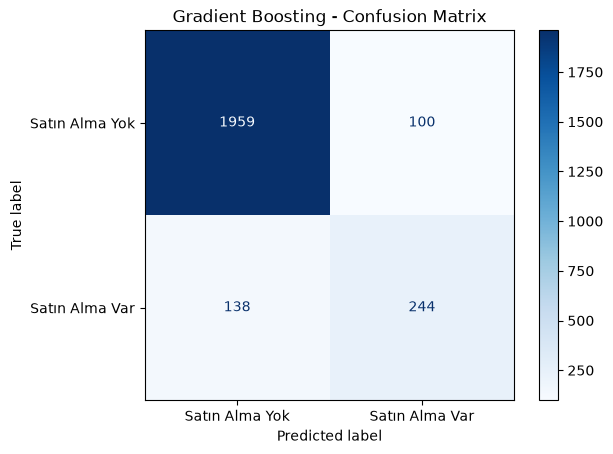

In [29]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Gradient Boosting tahminleri
best_baseline_model = models["Gradient Boosting"]
gb_predictions = best_baseline_model.predict(X_test_processed)

# Sınıflandırma raporu
print("Sınıflandırma Raporu:")
print(classification_report(
    y_test,
    gb_predictions,
    target_names=["Satın Alma Yok", "Satın Alma Var"]
))

# Confusion Matrix
cm = confusion_matrix(y_test, gb_predictions)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Satın Alma Yok", "Satın Alma Var"]
)

display.plot(cmap="Blues")
plt.title("Gradient Boosting - Confusion Matrix")
plt.show()

Gradient Boosting modelinin sınıflandırma raporu incelendiğinde, modelin satın alma yapmayan oturumları daha başarılı tahmin ettiği görülmektedir. Satın alma yapmayan sınıf için Precision %93, Recall %95 ve F1 Score %94 olarak hesaplanmıştır.

Satın alma yapan oturumlarda ise Precision %71, Recall %64 ve F1 Score %67 değerleri elde edilmiştir. Bu sonuç, modelin satın alma tahmini yaptığı oturumların önemli bir bölümünde doğru sonuç verdiğini, ancak gerçek satın alma oturumlarının yaklaşık %36'sını tespit edemediğini göstermektedir.

Genel doğruluk oranı %90 olmasına rağmen, sınıflar arasındaki dengesizlik nedeniyle yalnızca Accuracy değerine bakmak yeterli değildir. Bu nedenle satın alma yapan sınıfın Recall ve F1 Score değerleri model değerlendirmesinde özellikle dikkate alınmalıdır.

### 4.4.4 Confusion Matrix (Karmaşıklık Matrisi) Analizi

Gradient Boosting modelinin karmaşıklık matrisi incelendiğinde, modelin 1.959 satın alma gerçekleşmeyen oturumu ve 244 satın alma gerçekleşen oturumu doğru tahmin ettiği görülmektedir.

Bunun yanında model, gerçekte satın alma gerçekleşmeyen 100 oturumu yanlışlıkla satın alma olarak sınıflandırmıştır. Gerçekten satın alma gerçekleşen 138 oturumu ise tespit edememiştir.

İşletme açısından değerlendirildiğinde, kaçırılan satın alma oturumlarının azaltılması önemlidir. Çünkü bu oturumların doğru belirlenmesi, potansiyel müşterilere yönelik pazarlama faaliyetlerinin planlanmasına katkı sağlayabilir.

In [30]:
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import GradientBoostingClassifier

# Seyrek matrisi yoğun matrise dönüştürme
X_train_grid = (
    X_train_processed.toarray()
    if hasattr(X_train_processed, "toarray")
    else X_train_processed
)

# Gradient Boosting modeli
gb_model = GradientBoostingClassifier(random_state=42)

# Denenecek parametreler
param_grid = {
    "learning_rate": [0.05, 0.1],
    "n_estimators": [100, 150],
    "max_depth": [2, 3]
}

# GridSearchCV
grid_search = GridSearchCV(
    estimator=gb_model,
    param_grid=param_grid,
    scoring="f1",
    cv=5,
    n_jobs=-1,
    verbose=1
)

# Modelin eğitilmesi
grid_search.fit(X_train_grid, y_train)

print("En iyi parametreler:")
print(grid_search.best_params_)

print("\nEn iyi çapraz doğrulama F1 Score:")
print(grid_search.best_score_)

Fitting 5 folds for each of 8 candidates, totalling 40 fits
En iyi parametreler:
{'learning_rate': 0.1, 'max_depth': 2, 'n_estimators': 100}

En iyi çapraz doğrulama F1 Score:
0.6580325813117337


### 4.5.1 GridSearchCV ile Hiperparametre Optimizasyonu

Gradient Boosting modelinin performansını iyileştirmek amacıyla GridSearchCV yöntemi kullanılmıştır. Bu yöntemde 8 farklı parametre kombinasyonu, 5 katlı çapraz doğrulama ile değerlendirilmiştir.

Optimizasyon sonucunda en iyi parametreler aşağıdaki şekilde belirlenmiştir:

- learning_rate: 0.1
- max_depth: 2
- n_estimators: 100

En iyi çapraz doğrulama F1 Score değeri 0.6580 olarak elde edilmiştir.

Bu sonuç, modelin eğitim verisi üzerindeki farklı veri bölümlerinde gösterdiği ortalama performansı ifade etmektedir. Optimize edilmiş modelin nihai başarısı ayrıca test veri seti üzerinde değerlendirilecektir.

In [31]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# En iyi modelin alınması
best_model = grid_search.best_estimator_

# Test verisinin uygun formata dönüştürülmesi
X_test_grid = (
    X_test_processed.toarray()
    if hasattr(X_test_processed, "toarray")
    else X_test_processed
)

# Test verisi üzerinde tahmin
optimized_predictions = best_model.predict(X_test_grid)

# Performans ölçütleri
print("Optimize Edilmiş Gradient Boosting Modeli")
print("------------------------------------------")

print("Accuracy:", accuracy_score(y_test, optimized_predictions))
print("Precision:", precision_score(y_test, optimized_predictions))
print("Recall:", recall_score(y_test, optimized_predictions))
print("F1 Score:", f1_score(y_test, optimized_predictions))

print("\nSınıflandırma Raporu:")
print(classification_report(
    y_test,
    optimized_predictions,
    target_names=["Satın Alma Yok", "Satın Alma Var"]
))

Optimize Edilmiş Gradient Boosting Modeli
------------------------------------------
Accuracy: 0.9049569848422777
Precision: 0.7245508982035929
Recall: 0.6335078534031413
F1 Score: 0.6759776536312849

Sınıflandırma Raporu:
                precision    recall  f1-score   support

Satın Alma Yok       0.93      0.96      0.94      2059
Satın Alma Var       0.72      0.63      0.68       382

      accuracy                           0.90      2441
     macro avg       0.83      0.79      0.81      2441
  weighted avg       0.90      0.90      0.90      2441



### 4.5.2 Optimize Edilmiş Modelin Değerlendirilmesi

GridSearchCV sonucunda belirlenen en iyi parametrelerle Gradient Boosting modeli yeniden değerlendirilmiştir.

Optimize edilmiş modelin Accuracy değeri %90,50, Precision değeri %72,46, Recall değeri %63,35 ve F1 Score değeri %67,60 olarak hesaplanmıştır.

İlk Gradient Boosting modeliyle karşılaştırıldığında Accuracy, Precision ve F1 Score değerlerinde küçük artışlar görülürken Recall değerinde hafif bir düşüş meydana gelmiştir.

Bu sonuçlar, hiperparametre optimizasyonunun modelin genel performansını sınırlı ölçüde iyileştirdiğini göstermektedir. Ancak satın alma yapan oturumları yakalama oranında bir artış sağlanamamıştır.

In [32]:
comparison_df = pd.DataFrame({
    "Model": [
        "İlk Gradient Boosting",
        "Optimize Edilmiş Gradient Boosting"
    ],
    "Accuracy": [
        accuracy_score(y_test, gb_predictions),
        accuracy_score(y_test, optimized_predictions)
    ],
    "Precision": [
        precision_score(y_test, gb_predictions),
        precision_score(y_test, optimized_predictions)
    ],
    "Recall": [
        recall_score(y_test, gb_predictions),
        recall_score(y_test, optimized_predictions)
    ],
    "F1 Score": [
        f1_score(y_test, gb_predictions),
        f1_score(y_test, optimized_predictions)
    ]
})

comparison_df

,Model,Accuracy,Precision,Recall,F1 Score
0,İlk Gradient Boosting,0.902499,0.709302,0.638743,0.672176
1,Optimize Edilmiş Gradient Boosting,0.904957,0.724551,0.633508,0.675978


### 4.5.3 İlk ve Optimize Edilmiş Modelin Karşılaştırılması

İlk Gradient Boosting modeli ile hiperparametre optimizasyonu sonrasında elde edilen model karşılaştırılmıştır.

Karşılaştırma sonucunda optimize edilmiş modelin Accuracy değeri %90,50, F1 Score değeri ise %67,60 olmuştur. İlk modelde bu değerler sırasıyla %90,25 ve %67,22 olarak hesaplanmıştır.

Optimize edilmiş modelin Precision değerinde artış, Recall değerinde ise küçük bir düşüş görülmüştür. F1 Score değerindeki sınırlı artış, modelin genel performansında iyileşme olduğunu göstermektedir.

Bu nedenle optimize edilmiş Gradient Boosting modeli, mevcut değerlendirme sonuçlarına göre sonraki analizlerde kullanılmak üzere seçilmiştir.

In [33]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# PageValues değişkenini bağımsız değişkenlerden çıkarma
X_train_no_pagevalues = X_train.drop(columns=["PageValues"])
X_test_no_pagevalues = X_test.drop(columns=["PageValues"])

# Sayısal değişkenlerden PageValues'i çıkarma
numerical_features_no_pagevalues = [
    column for column in numerical_features
    if column != "PageValues"
]

# Yeni ön işleme yapısı
preprocessor_no_pagevalues = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features_no_pagevalues),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

# Eğitim ve test verilerinin dönüştürülmesi
X_train_no_pagevalues_processed = (
    preprocessor_no_pagevalues.fit_transform(X_train_no_pagevalues)
)

X_test_no_pagevalues_processed = (
    preprocessor_no_pagevalues.transform(X_test_no_pagevalues)
)

# Optimize edilmiş parametrelerle yeni model
model_no_pagevalues = GradientBoostingClassifier(
    **grid_search.best_params_,
    random_state=42
)

# Modelin eğitilmesi
model_no_pagevalues.fit(
    X_train_no_pagevalues_processed,
    y_train
)

# Tahmin
predictions_no_pagevalues = model_no_pagevalues.predict(
    X_test_no_pagevalues_processed
)

# Performans sonuçları
print("PageValues Olmadan Model Sonuçları")
print("----------------------------------")
print("Accuracy:", accuracy_score(y_test, predictions_no_pagevalues))
print("Precision:", precision_score(y_test, predictions_no_pagevalues))
print("Recall:", recall_score(y_test, predictions_no_pagevalues))
print("F1 Score:", f1_score(y_test, predictions_no_pagevalues))

PageValues Olmadan Model Sonuçları
----------------------------------
Accuracy: 0.8414584186808685
Precision: 0.43243243243243246
Recall: 0.041884816753926704
F1 Score: 0.07637231503579953


Model performansını etkileyen önemli değişkenlerden biri olan PageValues'in tahmin üzerindeki etkisini incelemek amacıyla bu değişken modelden çıkarılarak yeniden eğitim gerçekleştirilmiştir.

PageValues dahil edilen modelde F1 Score %67,60 ve Recall %63,35 olarak hesaplanmıştır. PageValues çıkarıldığında ise F1 Score %7,64'e, Recall değeri ise %4,19'a düşmüştür.

Bu belirgin performans düşüşü, PageValues değişkeninin modelin satın alma davranışını ayırt etmesinde çok güçlü bir bilgi taşıdığını göstermektedir.

Ancak PageValues değişkeninin satın alma işlemiyle ilişkili sayfa değerlerini yansıtması ve bu bilginin oturum tamamlandıktan sonra hesaplanabilme ihtimali, gerçek zamanlı tahmin açısından veri sızıntısı riski oluşturmaktadır.

Bu nedenle PageValues dahil edilen modelin yüksek performansı dikkatli değerlendirilmelidir. Gerçek satın alma öncesinde kullanılacak bir tahmin sistemi için yalnızca tahmin anında erişilebilir olan değişkenlerin kullanılması gerekmektedir.

PageValues Olmadan Sınıflandırma Raporu
                precision    recall  f1-score   support

Satın Alma Yok       0.85      0.99      0.91      2059
Satın Alma Var       0.43      0.04      0.08       382

      accuracy                           0.84      2441
     macro avg       0.64      0.52      0.49      2441
  weighted avg       0.78      0.84      0.78      2441



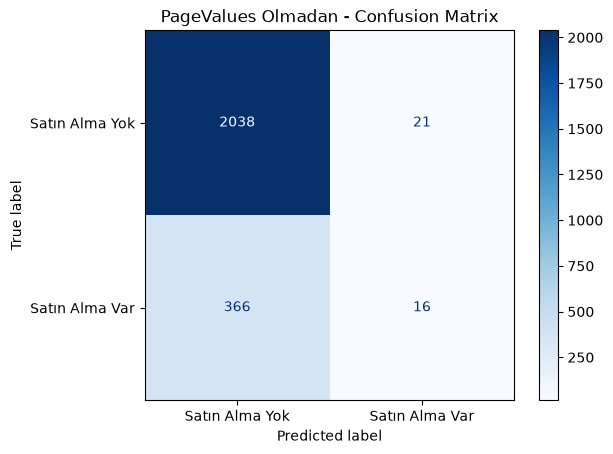

In [34]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

print("PageValues Olmadan Sınıflandırma Raporu")
print(classification_report(
    y_test,
    predictions_no_pagevalues,
    target_names=["Satın Alma Yok", "Satın Alma Var"]
))

cm_no_pagevalues = confusion_matrix(
    y_test,
    predictions_no_pagevalues
)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm_no_pagevalues,
    display_labels=["Satın Alma Yok", "Satın Alma Var"]
)

display.plot(cmap="Blues")
plt.title("PageValues Olmadan - Confusion Matrix")
plt.show()

PageValues değişkeni çıkarıldıktan sonra elde edilen sınıflandırma raporu incelendiğinde, modelin satın alma yapmayan oturumları oldukça başarılı tahmin ettiği görülmektedir. Bu sınıf için Recall değeri %99, F1 Score değeri ise %91'dir.

Buna karşılık satın alma yapan oturumlar için Recall yalnızca %4,19, F1 Score ise %7,64 olarak hesaplanmıştır. Bu durum, modelin gerçek satın alma oturumlarının yaklaşık %96'sını tespit edemediğini göstermektedir.

Genel Accuracy değerinin %84,15 olması tek başına yeterli bir başarı göstergesi değildir. Modelin çoğunluk sınıfına yönelmesi, veri setindeki sınıf dengesizliğinin etkisini ortaya koymaktadır.

In [35]:
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Sınıf ağırlıklarının hesaplanması
sample_weights = compute_sample_weight(
    class_weight="balanced",
    y=y_train
)

# PageValues olmadan, optimize edilmiş parametrelerle model
weighted_model = GradientBoostingClassifier(
    **grid_search.best_params_,
    random_state=42
)

# Ağırlıklı eğitim
weighted_model.fit(
    X_train_no_pagevalues_processed,
    y_train,
    sample_weight=sample_weights
)

# Tahmin
weighted_predictions = weighted_model.predict(
    X_test_no_pagevalues_processed
)

# Performans sonuçları
print("Sınıf Ağırlıklandırılmış Model Sonuçları")
print("---------------------------------------")
print("Accuracy:", accuracy_score(y_test, weighted_predictions))
print("Precision:", precision_score(y_test, weighted_predictions))
print("Recall:", recall_score(y_test, weighted_predictions))
print("F1 Score:", f1_score(y_test, weighted_predictions))

Sınıf Ağırlıklandırılmış Model Sonuçları
---------------------------------------
Accuracy: 0.662843097091356
Precision: 0.287776708373436
Recall: 0.7827225130890052
F1 Score: 0.42083040112596765


Sınıf dengesizliğinin model üzerindeki etkisini azaltmak amacıyla Gradient Boosting modelinde sınıf ağırlıklandırma yöntemi uygulanmıştır. Bu yöntemde azınlık sınıfı olan satın alma yapan oturumlara daha fazla ağırlık verilmiştir.

Ağırlıklandırma sonrasında Recall değeri %4,19'dan %78,27'ye yükselmiştir. Böylece model, gerçek satın alma oturumlarının çok daha büyük bir bölümünü tespit edebilmiştir.

Bununla birlikte Precision değeri %43,24'ten %28,78'e, Accuracy değeri ise %84,15'ten %66,28'e düşmüştür. F1 Score değeri ise %7,64'ten %42,08'e yükselmiştir.

Bu sonuçlar, sınıf ağırlıklandırmasının modelin satın alma yapan oturumları yakalama becerisini önemli ölçüde artırdığını, ancak yanlış pozitif tahminlerin de artmasına neden olduğunu göstermektedir. Dolayısıyla modelin performansı işletmenin hedeflerine göre değerlendirilmelidir.

Sınıf Ağırlıklandırılmış Model - Sınıflandırma Raporu
                precision    recall  f1-score   support

Satın Alma Yok       0.94      0.64      0.76      2059
Satın Alma Var       0.29      0.78      0.42       382

      accuracy                           0.66      2441
     macro avg       0.61      0.71      0.59      2441
  weighted avg       0.84      0.66      0.71      2441



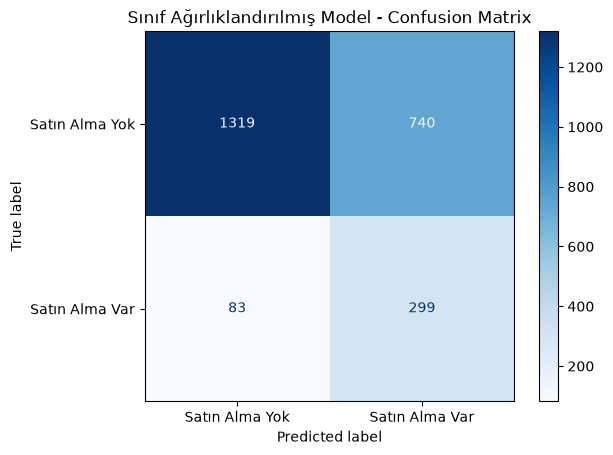

In [36]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

print("Sınıf Ağırlıklandırılmış Model - Sınıflandırma Raporu")

print(classification_report(
    y_test,
    weighted_predictions,
    target_names=["Satın Alma Yok", "Satın Alma Var"]
))

cm_weighted = confusion_matrix(y_test, weighted_predictions)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm_weighted,
    display_labels=["Satın Alma Yok", "Satın Alma Var"]
)

display.plot(cmap="Blues")
plt.title("Sınıf Ağırlıklandırılmış Model - Confusion Matrix")
plt.show()

Sınıf ağırlıklandırması sonrasında modelin Recall değeri önemli ölçüde artmış, ancak Precision değeri düşmüştür. Bu iki ölçüt arasında daha dengeli bir sonuç elde etmek amacıyla tahmin eşiğinin ayarlanması planlanmıştır.

Tahmin eşiğinin belirlenmesinde eğitim verisinden ayrılan bir doğrulama kümesi kullanılacaktır. En yüksek F1 Score değerini sağlayan eşik seçilecek ve modelin nihai performansı daha önce ayrılan test veri seti üzerinde değerlendirilecektir.

In [37]:
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import precision_recall_curve

# Eğitim verisini eğitim ve doğrulama olarak ayırma
X_train_sub, X_val, y_train_sub, y_val = train_test_split(
    X_train_no_pagevalues_processed,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

# Eğitim alt kümesi için sınıf ağırlıklarını hesaplama
sub_weights = compute_sample_weight(
    class_weight="balanced",
    y=y_train_sub
)

# Modeli eğitme
threshold_model = GradientBoostingClassifier(
    **grid_search.best_params_,
    random_state=42
)

threshold_model.fit(
    X_train_sub,
    y_train_sub,
    sample_weight=sub_weights
)

# Doğrulama verisi için satın alma olasılıklarını hesaplama
val_probabilities = threshold_model.predict_proba(X_val)[:, 1]

# Farklı eşikler için Precision ve Recall hesaplama
precision_values, recall_values, thresholds = precision_recall_curve(
    y_val,
    val_probabilities
)

# Her eşik için F1 Score hesaplama
f1_values = (
    2 * precision_values[:-1] * recall_values[:-1]
    / (precision_values[:-1] + recall_values[:-1] + 1e-10)
)

# En yüksek F1 Score değerini veren eşiği bulma
best_index = np.argmax(f1_values)
best_threshold = thresholds[best_index]

print("En iyi tahmin eşiği:", best_threshold)
print("Doğrulama verisindeki en yüksek F1 Score:", f1_values[best_index])
print("Bu eşikte Precision:", precision_values[best_index])
print("Bu eşikte Recall:", recall_values[best_index])

En iyi tahmin eşiği: 0.63454273505262
Doğrulama verisindeki en yüksek F1 Score: 0.4365620736212579
Bu eşikte Precision: 0.37383177570093457
Bu eşikte Recall: 0.5245901639344263


In [38]:
# Tüm eğitim verisi için sınıf ağırlıklarını hesaplama
final_weights = compute_sample_weight(
    class_weight="balanced",
    y=y_train
)

# Modeli tüm eğitim verisiyle yeniden eğitme
final_model = GradientBoostingClassifier(
    **grid_search.best_params_,
    random_state=42
)

final_model.fit(
    X_train_no_pagevalues_processed,
    y_train,
    sample_weight=final_weights
)

# Test verisi için satın alma olasılıklarını hesaplama
test_probabilities = final_model.predict_proba(
    X_test_no_pagevalues_processed
)[:, 1]

# Belirlenen eşikle sınıflandırma
final_predictions = (
    test_probabilities >= best_threshold
).astype(int)

# Nihai performans sonuçları
print("Nihai Model Sonuçları")
print("---------------------")
print("Accuracy:", accuracy_score(y_test, final_predictions))
print("Precision:", precision_score(y_test, final_predictions))
print("Recall:", recall_score(y_test, final_predictions))
print("F1 Score:", f1_score(y_test, final_predictions))

print("\nSınıflandırma Raporu:")
print(classification_report(
    y_test,
    final_predictions,
    target_names=["Satın Alma Yok", "Satın Alma Var"]
))

Nihai Model Sonuçları
---------------------
Accuracy: 0.7853338795575584
Precision: 0.3685185185185185
Recall: 0.5209424083769634
F1 Score: 0.4316702819956616

Sınıflandırma Raporu:
                precision    recall  f1-score   support

Satın Alma Yok       0.90      0.83      0.87      2059
Satın Alma Var       0.37      0.52      0.43       382

      accuracy                           0.79      2441
     macro avg       0.64      0.68      0.65      2441
  weighted avg       0.82      0.79      0.80      2441



Nihai model, PageValues değişkeni kullanılmadan, sınıf dengesizliğini dikkate alan örnek ağırlıkları ve doğrulama verisi üzerinde belirlenen sınıflandırma eşiği ile oluşturulmuştur. Modelin test verisi üzerindeki Accuracy değeri %78,53, Precision değeri %36,85, Recall değeri %52,09 ve F1 Score değeri %43,17 olarak elde edilmiştir.

Sonuçlar incelendiğinde modelin gerçek satın alma işlemlerinin yaklaşık %52'sini doğru tespit edebildiği görülmektedir. Ancak Precision değerinin görece düşük olması, satın alma yapacağı tahmin edilen ziyaretçilerin önemli bir bölümünün gerçekte satın alma gerçekleştirmediğini göstermektedir.

Bu sonuçlar, modelin potansiyel müşterileri belirleme konusunda belirli bir başarı sağladığını ancak yanlış pozitif tahminleri azaltmak için geliştirilmeye ihtiyaç duyduğunu ortaya koymaktadır. Modelin performansı değerlendirilirken yalnızca Accuracy değerine değil, özellikle Precision, Recall ve F1 Score metriklerine birlikte odaklanılmıştır.

In [39]:
model_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "Gradient Boosting",
        "Optimized Gradient Boosting",
        "Gradient Boosting (PageValues Hariç)",
        "Weighted Gradient Boosting",
        "Nihai Model"
    ],
    "Accuracy": [
        0.888570, 0.902499, 0.902499,
        0.904957, 0.841458, 0.662843, 0.785334
    ],
    "Precision": [
        0.761905, 0.758993, 0.709302,
        0.724551, 0.432432, 0.287777, 0.368519
    ],
    "Recall": [
        0.418848, 0.552356, 0.638743,
        0.633508, 0.041885, 0.782723, 0.520942
    ],
    "F1 Score": [
        0.540541, 0.639394, 0.672176,
        0.675978, 0.076372, 0.420830, 0.431670
    ]
})

model_comparison

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.888570,0.761905,0.418848,0.540541
1,Random Forest,0.902499,0.758993,0.552356,0.639394
2,Gradient Boosting,0.902499,0.709302,0.638743,0.672176
3,Optimized Gradient Boosting,0.904957,0.724551,0.633508,0.675978
4,Gradient Boosting (PageValues Hariç),0.841458,0.432432,0.041885,0.076372
5,Weighted Gradient Boosting,0.662843,0.287777,0.782723,0.420830
6,Nihai Model,0.785334,0.368519,0.520942,0.431670


Çalışma kapsamında Logistic Regression, Random Forest ve Gradient Boosting algoritmaları kullanılarak farklı modeller geliştirilmiş ve performansları Accuracy, Precision, Recall ve F1 Score metrikleri üzerinden karşılaştırılmıştır.

İlk model karşılaştırmasında optimize edilmiş Gradient Boosting modeli 0.676 F1 Score ile en yüksek performansı göstermiştir. Bununla birlikte bu model PageValues değişkenini içermektedir. PageValues değişkeninin tahmin anında kullanılabilirliği konusunda olası bir veri sızıntısı riski bulunduğundan, değişken modelden çıkarılarak ek değerlendirmeler yapılmıştır.

PageValues kullanılmadan oluşturulan modellerde sınıf ağırlıklandırma ve eşik optimizasyonu yöntemleri denenmiştir. Sınıf ağırlıklandırma yöntemi Recall değerini yükseltirken Precision değerinde düşüşe neden olmuştur. Nihai modelde ise doğrulama verisi üzerinde belirlenen sınıflandırma eşiği kullanılarak Precision ve Recall arasında farklı bir denge sağlanmıştır.

Sonuç olarak, modellerin başarısı yalnızca genel doğruluk oranına göre değerlendirilmemiş; satın alma gerçekleştiren ziyaretçileri tespit etme başarısı da dikkate alınmıştır. Nihai model, PageValues değişkenini kullanmayan alternatif olarak sonraki yorumlama ve değerlendirme aşamalarında esas alınmıştır.

In [40]:
feature_names = preprocessor_no_pagevalues.get_feature_names_out()

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": final_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

feature_importance.head(15)

,Feature,Importance
7,num__ExitRates,0.472482
5,num__ProductRelated_Duration,0.104206
0,num__Administrative,0.088737
19,cat__Month_Nov,0.083020
11,num__AverageProductPageDuration,0.048661
1,num__Administrative_Duration,0.023980
73,cat__VisitorType_Returning_Visitor,0.017866
6,num__BounceRates,0.017344
20,cat__Month_Oct,0.015877
24,cat__OperatingSystems_3,0.014380


5.1 Özellik Önemlerinin İncelenmesi (Feature Importance)

Nihai modelin özellik önemleri incelendiğinde, ExitRates değişkeninin %47,25 ile tahminlerde en yüksek öneme sahip olduğu görülmüştür. Bunu ProductRelated_Duration (%10,42), Administrative (%8,87), Month_Nov (%8,30) ve AverageProductPageDuration (%4,87) değişkenleri takip etmektedir.

Bu sonuçlar, ziyaretçilerin sayfalardan ayrılma davranışlarının ve ürün sayfalarında geçirdikleri sürenin satın alma tahmininde önemli rol oynadığını göstermektedir. Ayrıca ziyaret edilen yönetimsel sayfa sayısı ve ziyaretin gerçekleştiği ay da modelin tahminlerine katkıda bulunmaktadır.

Özellik önemleri, değişkenlerin model tahminlerine göreli katkısını göstermektedir. Ancak bu değerler değişkenler ile satın alma davranışı arasındaki ilişkinin yönünü veya nedenselliğini tek başına açıklamamaktadır.

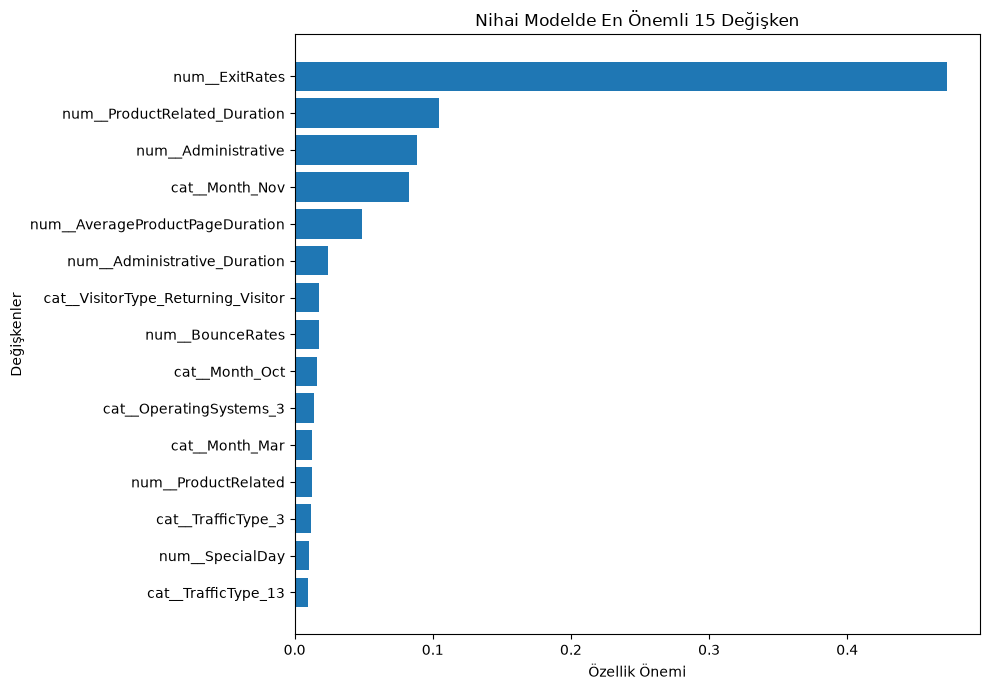

In [41]:
import matplotlib.pyplot as plt

top_features = feature_importance.head(15).sort_values(
    by="Importance",
    ascending=True
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.title("Nihai Modelde En Önemli 15 Değişken")
plt.xlabel("Özellik Önemi")
plt.ylabel("Değişkenler")
plt.tight_layout()
plt.show()

Grafik incelendiğinde ExitRates değişkeninin 0,47 civarındaki önem değeriyle diğer değişkenlerden belirgin biçimde ayrıldığı görülmektedir. İkinci sıradaki ProductRelated_Duration değişkeninin önem değeri ise yaklaşık 0,10 seviyesindedir. Bu fark, modelin tahminlerinde ExitRates değişkeninin çok daha baskın bir rol oynadığını göstermektedir.

Listenin son sıralarında yer alan TrafficType_13 değişkeninin önem değeri ise sıfıra oldukça yakındır. Bu durum, söz konusu değişkenin model tahminlerine katkısının diğer değişkenlere kıyasla oldukça sınırlı olduğunu göstermektedir.

Genel olarak grafik, ziyaretçilerin sayfalardan ayrılma davranışlarının satın alma tahmininde öne çıktığını ortaya koymaktadır.

5.3 İşletmeye Yönelik Yorumlama ve Öneriler

Model sonuçları, e-ticaret işletmelerinin ziyaretçi davranışlarını daha iyi anlamalarına ve pazarlama stratejilerini geliştirmelerine yardımcı olabilecek bulgular sunmaktadır.

Sayfa terk oranlarının azaltılması: ExitRates değişkeninin modelde en yüksek öneme sahip olması, ziyaretçilerin sayfalardan ayrılma davranışlarının dikkatle incelenmesi gerektiğini göstermektedir. İşletme, kullanıcı deneyimini, sayfa tasarımını ve alışveriş sürecini iyileştirebilir.

Ürün sayfalarının geliştirilmesi: ProductRelated_Duration değişkeninin önemi doğrultusunda ürün açıklamaları, görseller ve ürün önerileri geliştirilebilir.

Alışveriş sürecinin kolaylaştırılması: Administrative değişkeni incelenerek ziyaretçilerin alışveriş sürecinde karşılaştıkları gereksiz adımlar belirlenebilir.

Dönemsel pazarlama stratejileri: Month_Nov değişkeninin önemi dikkate alınarak Kasım ayındaki ziyaretçi ve satın alma davranışları analiz edilebilir ve kampanya planlamaları buna göre yapılabilir.

Bu öneriler, modelin ortaya koyduğu ilişkilerden hareketle oluşturulmuştur. Önerilen uygulamaların satın alma oranlarını gerçekten artırıp artırmadığı ayrıca ölçülmelidir.

5.4 Modelin İşletme Açısından Değerlendirilmesi

Geliştirilen makine öğrenmesi modeli, e-ticaret işletmelerinin ziyaretçi davranışlarını analiz ederek satın alma olasılığı yüksek oturumları belirlemesine yardımcı olabilecek bir karar destek aracı olarak değerlendirilebilir.

Model sayesinde işletme, pazarlama kampanyalarını planlarken potansiyel müşterilere öncelik verebilir ve pazarlama kaynaklarını daha bilinçli kullanabilir. Ayrıca özellik önemleri, ziyaretçilerin alışveriş davranışları hakkında işletmeye anlamlı bilgiler sunmaktadır.

Bununla birlikte nihai modelin Precision değerinin %36,85 olması, satın alma yapacağı tahmin edilen ziyaretçilerin önemli bir bölümünün gerçekte satın alma gerçekleştirmediğini göstermektedir. Bu nedenle modelin tahminleri kesin sonuçlar olarak değil, işletme kararlarını destekleyen tahminler olarak kullanılmalıdır.

Modelin gerçek iş sonuçlarına katkısını ölçmek için gelecekte kontrollü kampanyalar ve A/B testleri yapılması önerilmektedir.

6.1 Çalışmanın Sınırlılıkları

Bu çalışmanın bazı sınırlılıkları bulunmaktadır. Öncelikle kullanılan veri seti belirli bir döneme ait olduğundan günümüzdeki tüm e-ticaret kullanıcı davranışlarını temsil etmeyebilir.

İkinci olarak, veri setinde satın alma gerçekleştiren oturumların oranı satın alma gerçekleştirmeyen oturumlara kıyasla oldukça düşüktür. Bu sınıf dengesizliği modelin performansını ve sınıflandırma sonuçlarını etkilemiştir.

Ayrıca PageValues değişkeninin tahmin anında kullanılabilirliği konusunda olası bir veri sızıntısı riski bulunduğundan bu değişken nihai modelden çıkarılmıştır. Bu tercih modelin performansında belirgin bir düşüşe neden olmuştur.

Son olarak, nihai modelin Precision değerinin görece düşük olması, satın alma yapacağı tahmin edilen bazı ziyaretçilerin gerçekte satın alma gerçekleştirmediğini göstermektedir. Bu nedenle model tahminlerinin tek başına kesin işletme kararları vermek için kullanılmaması gerekir.

6.2 Gelecekte Yapılabilecek İyileştirmeler

Gelecekte yapılacak çalışmalarda modelin performansını artırmak ve farklı koşullarda genellenebilirliğini değerlendirmek amacıyla daha güncel ve kapsamlı veri setleri kullanılabilir.

XGBoost ve LightGBM gibi farklı makine öğrenmesi algoritmaları denenerek mevcut modellerle karşılaştırılabilir. Ayrıca sınıf dengesizliğini azaltmak amacıyla SMOTE gibi farklı veri dengeleme yöntemleri değerlendirilebilir.

Bunun yanında kullanıcıların alışveriş davranışlarını daha ayrıntılı açıklayan yeni değişkenler veri setine eklenebilir. Model gerçek bir e-ticaret ortamında test edilerek tahminlerinin işletme sonuçlarına katkısı A/B testleri aracılığıyla ölçülebilir.

Bu geliştirmeler, modelin farklı kullanıcı grupları ve dönemlerdeki performansını değerlendirmeye ve işletme açısından daha faydalı bir karar destek sistemi oluşturulmasına katkı sağlayabilir.

6.3 Genel Sonuç

Bu projede, online alışveriş oturumlarının satın alma ile sonuçlanıp sonuçlanmayacağını tahmin etmek amacıyla farklı makine öğrenmesi algoritmaları uygulanmıştır.

Veri temizleme, keşifsel veri analizi, özellik mühendisliği, modelleme ve performans değerlendirme aşamaları gerçekleştirilmiştir. Logistic Regression, Random Forest ve Gradient Boosting algoritmaları karşılaştırılmış; model performansını geliştirmek amacıyla hiperparametre optimizasyonu, sınıf ağırlıklandırma ve eşik optimizasyonu yöntemleri uygulanmıştır.

Analizler sonucunda ziyaretçilerin sayfalardan ayrılma davranışlarını gösteren ExitRates değişkeninin model tahminlerinde en yüksek öneme sahip olduğu belirlenmiştir. Nihai model, PageValues değişkeni kullanılmadan oluşturulmuş ve test verisinde %78,53 Accuracy ve %43,17 F1 Score elde etmiştir.

Sonuç olarak bu çalışma, makine öğrenmesi yöntemlerinin online alışveriş davranışlarını analiz etme ve satın alma olasılığı yüksek oturumları belirleme konusunda kullanılabileceğini göstermektedir. Geliştirilen model, e-ticaret işletmeleri için potansiyel müşterilerin belirlenmesine ve pazarlama kararlarının desteklenmesine yönelik bir başlangıç noktası sunmaktadır.